# Análisis del mercado inmobiliario en La Habana
**Proyecto de Ciencia de Datos — Universidad de La Habana**

Este cuaderno resume el proceso completo, paso a paso: carga de datos, corrección de precios, auditoría de calidad, comparación entre zonas y clustering.
Fuente: 92 anuncios de venta de viviendas en Revolico (una sola extracción). Los teléfonos fueron eliminados de los datos.
Necesita estos archivos en la misma carpeta: `inmuebles_habana_pro.csv`.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("inmuebles_habana_pro.csv")
print("Filas:", len(df), "| Columnas:", len(df.columns))
print(df[["Título", "Tipo_Inmueble", "Zona_Limpia", "Precio_Num"]].head(5).to_string())

Filas: 92 | Columnas: 34
                                                                                                      Título Tipo_Inmueble                  Zona_Limpia  Precio_Num
0                                                        Venta Apto 2 4 En Santo Suárez Municipio 10 Octubre   Apartamento                 Santo Suárez     25000.0
1  Apartamento Muy Luminoso (Pasillo No Edificio)En Bajos Muy Cerca De La Intersección De 100 Y 51, Marianao   Apartamento                     Marianao      8200.0
2                                              Apartamento Con Garaje En El Vedado ( Consejo Popular Rampa )   Apartamento                       Vedado     80000.0
3                                                                                   Apartamento En El Vedado   Apartamento                       Vedado     45000.0
4                                    Se Vende Hermosa Casa Colonial Con 8 Habitaciones Extras Para Alquilar!          Casa  Otra Zona / No Especificada    

## 1. Corrección de precios
La columna `Precio_Num` tiene errores de extracción (por ejemplo, 560,000 cuando el anuncio decía 60,000).
Solución: leer el precio que aparece escrito en el texto del anuncio (`... USD`).

In [2]:
def precio_real(txt, fallback):
    m = re.search(r'(\d{1,3}(?:,\d{3})+|\d+)\s*USD', str(txt))
    return float(m.group(1).replace(",", "")) if m else fallback

df["Precio_original"] = df["Precio_Num"]
df["Precio"] = [precio_real(d, p) for d, p in zip(df["Descripción"], df["Precio_Num"])]
cambiados = df[df["Precio"] != df["Precio_original"]]
print("Precios corregidos:", len(cambiados), "de", len(df))
print(cambiados[["Precio_original", "Precio"]].head(6).to_string())
print()
print("Promedio original:", round(df["Precio_original"].mean()), "| corregido:", round(df["Precio"].mean()))
print("Mediana  original:", df["Precio_original"].median(), "| corregida:", df["Precio"].median())

Precios corregidos: 16 de 92
    Precio_original   Precio
34         560000.0  60000.0
51         412000.0  12000.0
61         660000.0  60000.0
62         618000.0  18000.0
64         617000.0  17000.0
65         665000.0  65000.0

Promedio original: 159776 | corregido: 66298
Mediana  original: 29500.0 | corregida: 25000.0

## 2. Auditoría de calidad
Revisamos: municipio según Revolico (más fiable que la zona deducida del texto), anuncios casi duplicados y anuncios sin descripción.

In [3]:
df["Municipio"] = df["Descripción"].str.extract(r'visitas?\s+([A-Za-zÁÉÍÓÚáéíóúñÑ ]+?),\s*La Habana')[0]
df["Municipio"] = df["Municipio"].replace({"Plaza": "Plaza de la Revolución"})

def cuerpo(t):
    t = str(t); i = t.find("Guardar Más"); t = t[i + 11:] if i >= 0 else t
    t = re.sub(r'\[tel\]|\d+', '#', t.lower())
    t = re.sub(r'publicidad|llamar|whatsapp', '', t)
    t = re.sub(r'[^a-záéíóúñ# ]', '', t)
    return re.sub(r'\s+', ' ', t).strip()[:60]

df["_clave"] = df["Descripción"].map(cuerpo)
sin_detalle = df["_clave"].str.replace("#", "").str.strip().str.len() < 25
duplicado = (~sin_detalle) & df.duplicated(["Municipio", "_clave"], keep="first")

print("Anuncios sin descripción (solo teléfono):", int(sin_detalle.sum()))
print("Anuncios casi duplicados:", int(duplicado.sum()))
print("Zonas 'Otra zona / No especificada':", int((df["Zona_Limpia"] == "Otra Zona / No Especificada").sum()))
print()
print(df["Municipio"].value_counts().to_string())

Anuncios sin descripción (solo teléfono): 12
Anuncios casi duplicados: 2
Zonas 'Otra zona / No especificada': 13

Municipio
Diez de Octubre           20
Playa                     20
Plaza de la Revolución    19
Centro Habana              8
Cerro                      6
Habana del Este            6
Arroyo Naranjo             5
Marianao                   2
La Lisa                    2
Cotorro                    1
Habana Vieja               1
Guanabacoa                 1
San Miguel del Padrón      1

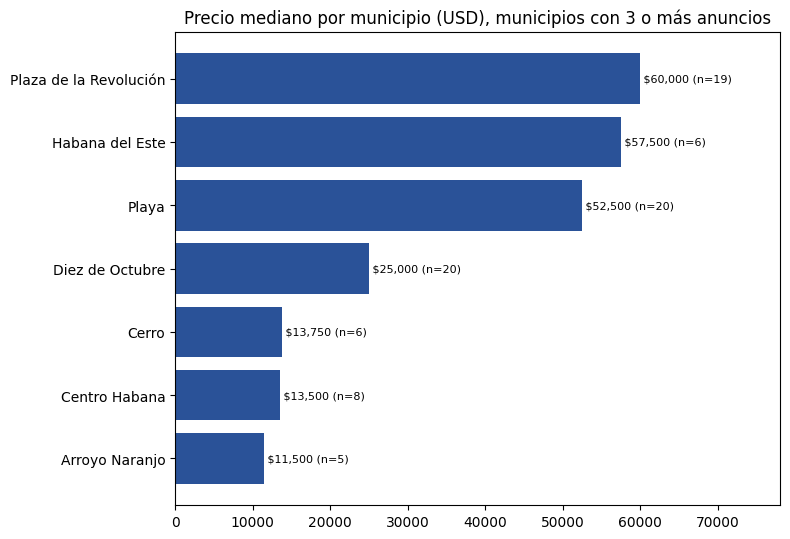

In [4]:
g = df.groupby("Municipio")["Precio"].agg(["median", "count"])
g = g[g["count"] >= 3].sort_values("median")
plt.figure(figsize=(8, 5.5))
plt.barh(g.index, g["median"], color="#2a5298")
for i, (v, k) in enumerate(zip(g["median"], g["count"])):
    plt.text(v, i, f" ${v:,.0f} (n={k})", va="center", fontsize=8)
plt.xlim(0, g["median"].max() * 1.3)
plt.title("Precio mediano por municipio (USD), municipios con 3 o más anuncios")
plt.tight_layout(); plt.show()

## 3. ¿Qué tan estables son los resultados?
La mediana casi no cambia al corregir o quitar duplicados; el promedio sí cambia mucho porque unos pocos anuncios de lujo (y los errores de precio) lo distorsionan.

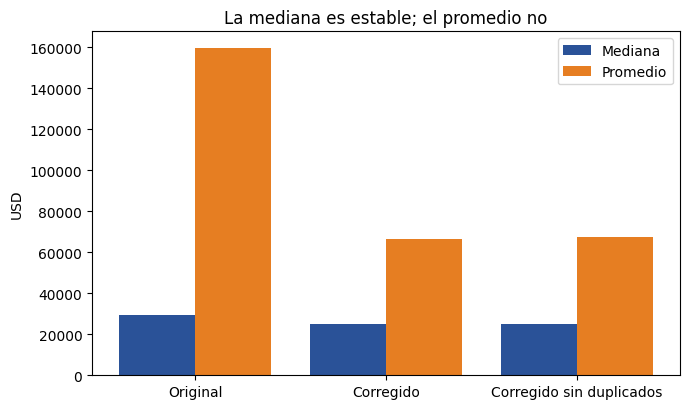

In [5]:
sin_dup = df[~duplicado]["Precio"]
nombres = ["Original", "Corregido", "Corregido sin duplicados"]
med = [df["Precio_original"].median(), df["Precio"].median(), sin_dup.median()]
prom = [df["Precio_original"].mean(), df["Precio"].mean(), sin_dup.mean()]
x = np.arange(3)
plt.figure(figsize=(7, 4.2))
plt.bar(x - 0.2, med, 0.4, label="Mediana", color="#2a5298")
plt.bar(x + 0.2, prom, 0.4, label="Promedio", color="#e67e22")
plt.xticks(x, nombres); plt.ylabel("USD"); plt.legend()
plt.title("La mediana es estable; el promedio no")
plt.tight_layout(); plt.show()

## 4. Precio por tipo de inmueble

                median  count
Tipo_Inmueble                
Otro            8000.0      1
Apartamento    17500.0     46
Casa           27000.0     38
Biplanta       47500.0      6
Finca          65000.0      1

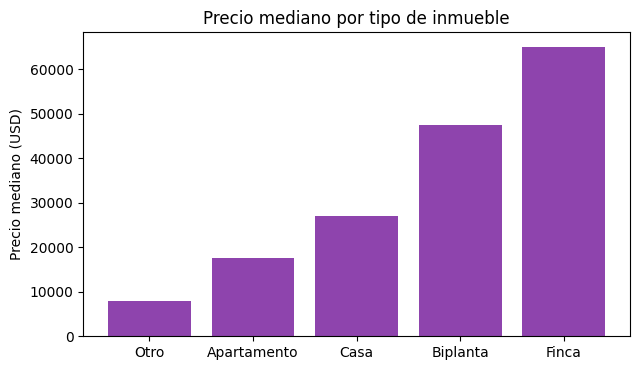

In [6]:
t = df.groupby("Tipo_Inmueble")["Precio"].agg(["median", "count"]).sort_values("median")
print(t.to_string())
plt.figure(figsize=(6.5, 3.8))
plt.bar(t.index, t["median"], color="#8e44ad")
plt.ylabel("Precio mediano (USD)")
plt.title("Precio mediano por tipo de inmueble")
plt.tight_layout(); plt.show()

## 5. Clustering (K-Means con NumPy)
Variables: logaritmo del precio, cuartos, baños y cantidad de servicios o características mencionadas.
Los grupos resultantes separan sobre todo el **nivel de detalle** del anuncio y un grupo pequeño de casas de lujo; no es una segmentación de mercado definitiva.

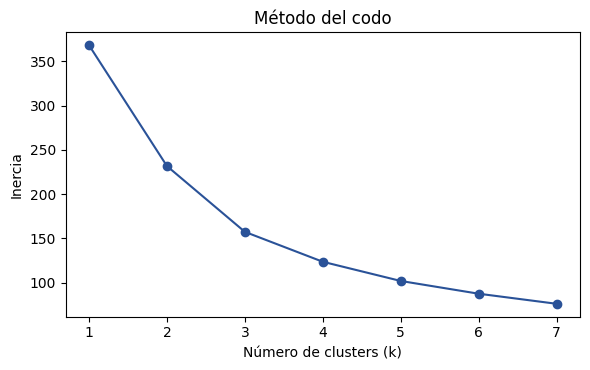

In [7]:
df = df[df["Precio"] >= 1000].reset_index(drop=True)
extras = ["Agua", "Luz", "Gas", "Teléfono", "Patio", "Terraza", "Balcon", "Jardín",
          "Piscina", "Garaje", "Placa_Libre", "Independiente"]
df["N_extras"] = (df[extras] == "Sí").sum(axis=1)
df["log_precio"] = np.log10(df["Precio"])
X = df[["log_precio", "Cuartos", "Baños", "N_extras"]].astype(float).values
Xs = (X - X.mean(axis=0)) / X.std(axis=0)

def kmeans(X, k, iters=100, seed=0):
    rng = np.random.default_rng(seed)
    cent = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        d = ((X[:, None, :] - cent[None, :, :]) ** 2).sum(axis=2)
        lab = d.argmin(axis=1)
        nuevo = np.array([X[lab == j].mean(axis=0) if (lab == j).any() else cent[j] for j in range(k)])
        if np.allclose(nuevo, cent):
            break
        cent = nuevo
    return lab, cent, ((X - cent[lab]) ** 2).sum()

ks = range(1, 8)
inercias = [min(kmeans(Xs, k, seed=s)[2] for s in range(10)) for k in ks]
plt.figure(figsize=(6, 3.8))
plt.plot(list(ks), inercias, marker="o", color="#2a5298")
plt.xlabel("Número de clusters (k)"); plt.ylabel("Inercia"); plt.title("Método del codo")
plt.tight_layout(); plt.show()

                Anuncios  Precio_mediano  Cuartos  Banos  Extras
Segmento                                                        
Poco detallado        57         25000.0      0.3    0.1     1.2
Detallado             30         21000.0      2.2    0.9     4.0
Lujo                   5        600000.0      6.4    5.6     1.4

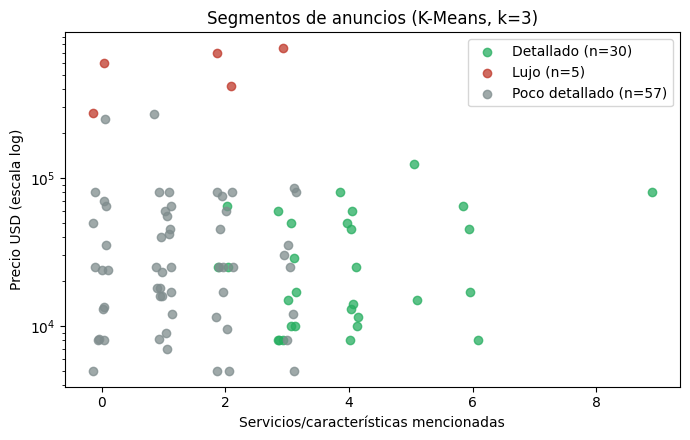

In [8]:
K = 3
mejor = min((kmeans(Xs, K, seed=s) for s in range(20)), key=lambda r: r[2])
df["Cluster"] = mejor[0]
lujo = df.groupby("Cluster")["Precio"].median().idxmax()
resto = [c for c in df["Cluster"].unique() if c != lujo]
detallado = max(resto, key=lambda c: df.loc[df["Cluster"] == c, "Cuartos"].mean())
nombres = {lujo: "Lujo", detallado: "Detallado", **{c: "Poco detallado" for c in resto if c != detallado}}
df["Segmento"] = df["Cluster"].map(nombres)

perfil = df.groupby("Segmento").agg(Anuncios=("Precio", "count"), Precio_mediano=("Precio", "median"),
                                    Cuartos=("Cuartos", "mean"), Banos=("Baños", "mean"),
                                    Extras=("N_extras", "mean")).round(1)
print(perfil.reindex(["Poco detallado", "Detallado", "Lujo"]).to_string())

colores = {"Poco detallado": "#7f8c8d", "Detallado": "#27ae60", "Lujo": "#c0392b"}
plt.figure(figsize=(7, 4.5))
for seg, gr in df.groupby("Segmento"):
    plt.scatter(gr["N_extras"] + np.random.default_rng(0).uniform(-.15, .15, len(gr)), gr["Precio"],
                label=f"{seg} (n={len(gr)})", color=colores[seg], alpha=.75)
plt.yscale("log"); plt.legend()
plt.xlabel("Servicios/características mencionadas"); plt.ylabel("Precio USD (escala log)")
plt.title("Segmentos de anuncios (K-Means, k=3)")
plt.tight_layout(); plt.show()

## Conclusiones preliminares
- Con los precios corregidos, la **mediana es de 25,000 USD** (el promedio, unos 66,000, lo distorsionan pocos anuncios de lujo).
- Por municipio, los más caros son Plaza de la Revolución, Habana del Este (Guanabo) y Playa; los más baratos, Centro Habana, Cerro y Arroyo Naranjo.
- Hubo errores de extracción en 16 de 92 precios, 10 zonas mal asignadas, 13 sin zona y 2 anuncios casi duplicados.
- El clustering separa el nivel de detalle del anuncio más que tipos de mercado.

## Limitaciones
Muestra pequeña (92 anuncios, una sola extracción). Varios municipios tienen 1 o 2 anuncios. Los precios son de oferta, no de cierre.
Las entrevistas a personas e inmobiliarias están en proceso y se agregarán de forma anónima.